# 급식 잔반 예보 — 메뉴 기반 잔반량 예측 & 감축 추천

작년 한 해 조식/중식/석식 잔반량(kg) 데이터 + 나이스(NEIS) 급식식단정보 오픈API를 결합해
`RandomForestRegressor`로 잔반량을 학습하고, 특정 메뉴를 뺐을 때 예상되는
잔반 감소량 → 탄소 감축량 → 급식비 절감액을 추천합니다.

**실행 전에 아래 3가지를 꼭 준비하세요**
1. 나이스 오픈API 인증키 (https://open.neis.go.kr, 무료 즉시 발급)
2. 학교가 속한 시도교육청 코드(ATPT_OFCDC_SC_CODE)
3. 학교 행정표준코드(SD_SCHUL_CODE) — 나이스 학교 검색 API나 학교알리미에서 확인 가능

이 노트북의 셀을 위에서부터 순서대로 실행하면 됩니다. 데이터 파일(`2025년도_음식물폐기물_처리량.xlsx`)은
코랩 좌측 파일 탭에 먼저 업로드해 두세요.

In [2]:
!pip install requests pandas scikit-learn matplotlib openpyxl -q

import re
import time
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MultiLabelBinarizer

plt.rcParams["font.family"] = "NanumGothic"  # 코랩에 한글 폰트 없으면 아래 셀 참고
plt.rcParams["axes.unicode_minus"] = False

### 한글 폰트가 깨질 경우 (그래프에 네모만 보일 때)
아래 셀의 주석을 풀고 한 번 실행한 뒤, **런타임 재시작** 후 다시 위에서부터 실행하세요.

In [3]:
!sudo apt-get -y install fonts-nanum -q
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (5,262 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122809 files and directories cur

## 1. 설정값 — 반드시 본인 학교 정보로 채우세요

In [4]:
# ====== 필수 설정값 ======
NEIS_API_KEY = "7a938fd071134d33bf9fe0958f603158"
ATPT_OFCDC_SC_CODE = "S10"   # 예: 경상남도교육청 = "G10"
SD_SCHUL_CODE = "9010081"

WASTE_FILE_PATH = "2025년도 음식물폐기물 처리량(csv+이상치제거).csv"  # 코랩에 업로드한 실제 파일명
# 끼니 이름 -> 나이스 API MMEAL_SC_CODE
MEAL_CODE_MAP = {"조식": "1", "중식": "2", "석식": "3"}

# ====== 환산 계수 (근거 데이터로 교체 가능) ======
CARBON_FACTOR_KG_CO2_PER_KG_WASTE = 2.5   # 음식물쓰레기 1kg당 탄소배출량(kgCO2eq) 추정치
COST_PER_KG_WON = 3000                    # 급식 재료비 환산 단가(원/kg) 추정치

## 2. 잔반량 데이터 불러오기 (CSV, 날짜 형식 자동 인식)

날짜("일자") 값이 여전히 엑셀 시리얼 숫자로 남아있으면 자동으로 실제 날짜로 변환하고,
이미 보통 날짜 문자열(예: 2025-03-04)로 저장돼 있으면 그대로 인식합니다.

In [5]:
waste_df = pd.read_csv(WASTE_FILE_PATH, encoding="utf-8-sig")
waste_df.columns = ["일자", "끼니", "발생량"]

# 빈 줄(값이 모두 비어있는 행) 제거
waste_df = waste_df.dropna(subset=["일자", "끼니", "발생량"]).reset_index(drop=True)

def parse_date(value):
    # 숫자(엑셀 시리얼 날짜)면 시리얼 변환, 이미 날짜 형식 문자열이면 그대로 파싱
    try:
        serial = float(value)
        return (datetime(1899, 12, 30) + timedelta(days=int(serial))).date()
    except (ValueError, TypeError):
        return pd.to_datetime(value).date()

waste_df["날짜"] = waste_df["일자"].apply(parse_date)
waste_df["끼니코드"] = waste_df["끼니"].map(MEAL_CODE_MAP)
waste_df["발생량"] = waste_df["발생량"].astype(float)

print(f"총 {len(waste_df)}건, 기간 {waste_df['날짜'].min()} ~ {waste_df['날짜'].max()}")
waste_df.head()

총 791건, 기간 2025-01-01 ~ 2025-12-31


,일자,끼니,발생량,날짜,끼니코드
0,2025-01-01,조식,5.0,2025-01-01,1
1,2025-01-01,중식,9.0,2025-01-01,2
2,2025-01-01,석식,9.0,2025-01-01,3
3,2025-01-02,조식,6.0,2025-01-02,1
4,2025-01-02,중식,11.0,2025-01-02,2


## 3. 나이스 급식식단정보 API로 날짜별 메뉴 가져오기

같은 (날짜, 끼니) 조합은 캐시에 저장해 중복 호출을 막습니다.
학교 데이터가 1년치라 호출 수가 꽤 많으니, 실행 중 끊기면 이 셀만 다시 실행해도
`menu_cache`에 남은 것부터 이어서 진행됩니다.

In [6]:
menu_cache = {}

def fetch_menu(date_obj, meal_code):
    key = (date_obj, meal_code)
    if key in menu_cache:
        return menu_cache[key]

    ymd = date_obj.strftime("%Y%m%d")
    url = "https://open.neis.go.kr/hub/mealServiceDietInfo"
    params = {
        "KEY": NEIS_API_KEY,
        "Type": "json",
        "ATPT_OFCDC_SC_CODE": ATPT_OFCDC_SC_CODE,
        "SD_SCHUL_CODE": SD_SCHUL_CODE,
        "MLSV_YMD": ymd,
        "MMEAL_SC_CODE": meal_code,
    }
    dish_list = []
    try:
        res = requests.get(url, params=params, timeout=10)
        data = res.json()
        dish_raw = data["mealServiceDietInfo"][1]["row"][0]["DDISH_NM"]
        # 알레르기 표기 숫자 및 줄바꿈 태그 제거
        dishes = re.sub(r"\([\d\.]+\)", "", dish_raw)
        dish_list = [d.strip() for d in dishes.split("<br/>") if d.strip()]
    except Exception:
        dish_list = []  # 급식이 없는 날(방학·주말 등) 또는 API 오류

    menu_cache[key] = dish_list
    time.sleep(0.15)  # 과다호출 방지
    return dish_list

waste_df["메뉴"] = [
    fetch_menu(d, c) for d, c in zip(waste_df["날짜"], waste_df["끼니코드"])
]

# 메뉴를 못 가져온(빈 리스트) 행 개수 확인
print("메뉴 조회 실패/없음:", (waste_df["메뉴"].apply(len) == 0).sum(), "건")
waste_df.to_pickle("waste_with_menu.pkl")  # 중간 결과 저장 (재실행 대비)
waste_df.head()

메뉴 조회 실패/없음: 2 건


,일자,끼니,발생량,날짜,끼니코드,메뉴
0,2025-01-01,조식,5.0,2025-01-01,1,"[브로콜리크림스프, 떡국, 배추김치, 귤, 피자호빵, 초코첵스/우유]"
1,2025-01-01,중식,9.0,2025-01-01,2,"[친환경쌀밥, 들깨미역국, 야채계란찜, 참나물겉절이, 순살곱도리탕, 배추김치, 골드..."
2,2025-01-01,석식,9.0,2025-01-01,3,"[찰보리밥, 푸실리토마토소스볶음, 플라워파이, 굴림만두국, 마늘쫑간장조림, 투움바함..."
3,2025-01-02,조식,6.0,2025-01-02,1,"[혼합잡곡밥, 차돌박이된장찌개, 훈제닭바베큐/머스터드, 감자햄볶음, 배추김치, 에그..."
4,2025-01-02,중식,11.0,2025-01-02,2,"[노랑차조밥, 야채비빔국수, 꽃게매운탕, 양파간장절임, 돼지갈비구이, 배추김치, 천혜향]"


## 4. 특징(feature) 만들기 — 끼니 + 메뉴 조합만 사용 (날짜 요인 제외)

In [ ]:
# 메뉴를 못 가져온 행은 학습에서 제외
train_df = waste_df[waste_df["메뉴"].apply(len) > 0].reset_index(drop=True)

all_dishes = [d for dishes in train_df["메뉴"] for d in dishes]
top_dishes = pd.Series(all_dishes).value_counts().index.tolist()  # 등장한 모든 메뉴 사용 (개수 제한 없음)

mlb = MultiLabelBinarizer(classes=top_dishes)
dish_matrix = mlb.fit_transform(
    train_df["메뉴"].apply(lambda dishes: [d for d in dishes if d in top_dishes])
)
dish_features = pd.DataFrame(dish_matrix, columns=top_dishes, index=train_df.index)

# 날짜 요인(요일·월)은 사용하지 않음 — 처음 보는 메뉴 조합이라도
# "끼니 + 메뉴"만으로 예측할 수 있도록 구성
meal_dummies = pd.get_dummies(train_df["끼니"], prefix="끼니")

X = pd.concat([dish_features, meal_dummies], axis=1)
y = train_df["발생량"]

print("학습 샘플 수:", len(X), " / 메뉴 종류 수:", len(top_dishes), " / 특징 수:", X.shape[1])

학습 샘플 수: 789  / 메뉴 종류 수: 1321  / 특징 수: 1324


## 5. RandomForestRegressor 학습

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=300, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"MAE  : {mae:.2f} kg")
print(f"RMSE : {rmse:.2f} kg")

MAE  : 1.82 kg
RMSE : 2.97 kg


## 6. 어떤 요인이 잔반량에 큰 영향을 주는지 확인

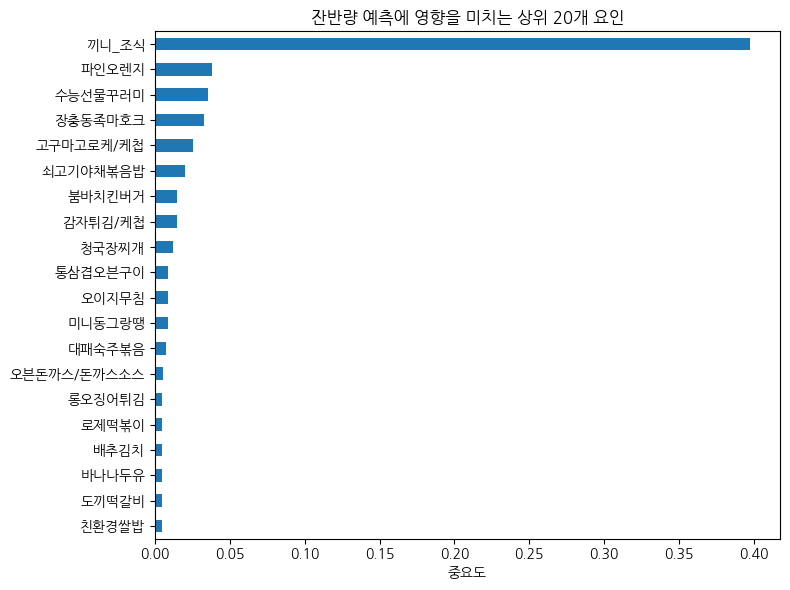

In [ ]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
top20 = importance.head(20)

plt.figure(figsize=(8, 6))
top20[::-1].plot(kind="barh")
plt.title("잔반량 예측에 영향을 미치는 상위 20개 요인")
plt.xlabel("중요도")
plt.tight_layout()
plt.show()

## 7. 메뉴 감축 추천

특정 날짜·끼니의 예정 메뉴를 넣으면, 그중 어떤 메뉴를 빼면(=조리량을 줄이면)
잔반이 얼마나 줄어들지, 그게 탄소 배출/급식비로 얼마인지 계산해 줍니다.

※ 이 값은 '해당 메뉴가 있고 없고'의 차이를 모델이 추정한 것이지 인과관계를 증명한 것은 아닙니다.
발표에서는 "모델이 추정한 감축 잠재량"이라고 표현하는 것이 정직합니다.

In [ ]:
def build_feature_row(meal_name, dish_list):
    row = {d: (1 if d in dish_list else 0) for d in top_dishes}
    for m in ["조식", "중식", "석식"]:
        col = f"끼니_{m}"
        if col in X.columns:
            row[col] = 1 if m == meal_name else 0
    return pd.DataFrame([row])[X.columns]

def recommend_reduction(meal_name, planned_dishes):
    base_pred = model.predict(build_feature_row(meal_name, planned_dishes))[0]

    results = []
    for dish in planned_dishes:
        if dish not in top_dishes:
            continue
        reduced = [d for d in planned_dishes if d != dish]
        new_pred = model.predict(build_feature_row(meal_name, reduced))[0]
        delta = base_pred - new_pred
        if delta > 0:
            results.append({
                "메뉴": dish,
                "예상감소_kg": round(delta, 2),
                "탄소감축_kgCO2eq": round(delta * CARBON_FACTOR_KG_CO2_PER_KG_WASTE, 2),
                "절감액_원": round(delta * COST_PER_KG_WON),
            })

    result_df = pd.DataFrame(results).sort_values("예상감소_kg", ascending=False).reset_index(drop=True)
    print(f"[{meal_name}] 모델 예측 잔반량: {round(base_pred, 2)} kg")
    return result_df

# 사용 예시 (실제 예정 메뉴로 바꿔서 실행하세요)
recommend_reduction("중식", ["잡곡밥", "된장찌개", "제육볶음", "무생채", "요구르트"])

[중식] 모델 예측 잔반량: 12.24 kg


,메뉴,예상감소_kg,탄소감축_kgCO2eq,절감액_원
0,무생채,0.83,2.07,2480
1,제육볶음,0.06,0.15,180


## 다음에 점진적으로 추가할 수 있는 요인 (요청하신 대로)
- 기온·날씨 (기상청 API 연동)
- 시험기간 여부 (학사일정 수동 입력 또는 학교 캘린더 연동)
- 특식/이벤트 급식 여부
- 직전 며칠간의 평균 잔반량(이동평균) → 추세 반영
- 알레르기 유발 식품 여부, 잔반 원인 설문 결과

각 요인을 추가할 때는 `X`에 컬럼만 추가하고 다시 5번 셀부터 재실행하면 됩니다.

## 8. 영양사 선생님용 잔반량 예측 프로그램

메뉴 이름을 직접 타이핑하면 오타나 학습되지 않은 메뉴명 때문에 예측이 틀어질 수 있어서,
학습된 메뉴만 카테고리(밥류·국류·간식류 등)에서 번호로 골라 조합하는 방식입니다.

1. 끼니(조식/중식/석식)를 입력합니다.
2. 카테고리 번호를 입력해 메뉴를 하나씩 고릅니다.
3. 다 골랐으면 **s**를 입력하면 그 메뉴 조합의 예상 잔반량 · 탄소감축 · 절감액을 계산합니다.

In [ ]:
# ====== 학습된 메뉴를 카테고리로 자동 분류 ======
CATEGORY_KEYWORDS = {
    "1.밥류": ["밥", "덮밥", "볶음밥", "비빔밥", "주먹밥", "죽"],
    "2.국·찌개류": ["국", "찌개", "탕", "전골"],
    "3.면류": ["면", "국수", "파스타", "스파게티", "라면"],
    "4.주찬류(고기·생선 등)": ["구이", "조림", "볶음", "튀김", "까스", "전", "강정", "찜"],
    "5.김치·나물·밑반찬류": ["김치", "나물", "무침", "장아찌", "샐러드", "겉절이"],
    "6.간식·후식류": ["과일", "요구르트", "우유", "주스", "빵", "떡", "젤리", "아이스크림", "사과", "귤"],
}

def categorize_dish(dish_name):
    for category, keywords in CATEGORY_KEYWORDS.items():
        if any(kw in dish_name for kw in keywords):
            return category
    return "7.기타"

dish_by_category = {}
for dish in top_dishes:
    cat = categorize_dish(dish)
    dish_by_category.setdefault(cat, []).append(dish)

for cat in dish_by_category:
    dish_by_category[cat] = sorted(dish_by_category[cat])

for cat in sorted(dish_by_category):
    print(f"{cat} : {len(dish_by_category[cat])}개")

1.밥류 : 113개
2.국·찌개류 : 146개
3.면류 : 29개
4.주찬류(고기·생선 등) : 253개
5.김치·나물·밑반찬류 : 104개
6.간식·후식류 : 129개
7.기타 : 547개


In [ ]:
def run_menu_waste_predictor():
    print("=" * 50)
    print("급식 잔반량 예측 프로그램")
    print("=" * 50)

    meal_name = ""
    while meal_name not in MEAL_CODE_MAP:
        meal_name = input("끼니를 입력하세요 (조식 / 중식 / 석식): ").strip()

    selected_dishes = []
    categories = sorted(dish_by_category.keys())

    while True:
        print("[카테고리 목록]")
        for cat in categories:
            print(f"  {cat}")
        print("  0 : 마지막으로 선택한 메뉴 취소")
        print("  s : 메뉴 선택 완료 → 잔반량 계산")
        print(f"현재 선택된 메뉴: {selected_dishes if selected_dishes else '(없음)'}")

        choice = input("카테고리 번호를 입력하세요 (완료하려면 s 입력): ").strip().lower()

        if choice == "s":
            break

        if choice == "0":
            if selected_dishes:
                removed = selected_dishes.pop()
                print(f">> '{removed}' 선택을 취소했습니다.")
            else:
                print(">> 취소할 메뉴가 없습니다.")
            continue

        matched_cat = next((c for c in categories if c.startswith(choice + ".")), None)
        if matched_cat is None:
            print(">> 목록에 없는 번호입니다. 다시 입력하세요.")
            continue

        # 카테고리 안 메뉴는 가나다 순으로 정렬되어 있음
        dish_options = dish_by_category[matched_cat]

        while True:
            print(f"[{matched_cat}] 메뉴 목록")
            for i, dish in enumerate(dish_options, 1):
                print(f"  {i}. {dish}")
            print("  0. 뒤로가기 (선택하지 않고 카테고리 목록으로)")

            d_choice = input("메뉴 번호를 입력하세요: ").strip()

            if d_choice == "0":
                break  # 아무것도 선택하지 않고 카테고리 목록으로 복귀

            try:
                dish = dish_options[int(d_choice) - 1]
                if dish not in selected_dishes:
                    selected_dishes.append(dish)
                print(f">> '{dish}' 추가되었습니다.")
                break  # 하나 선택했으면 카테고리 목록으로 복귀
            except (ValueError, IndexError):
                print(">> 잘못된 번호입니다. 다시 선택하세요.")

    if not selected_dishes:
        print("선택된 메뉴가 없어 계산을 종료합니다.")
        return

    predicted_kg = model.predict(build_feature_row(meal_name, selected_dishes))[0]
    carbon = predicted_kg * CARBON_FACTOR_KG_CO2_PER_KG_WASTE
    cost = predicted_kg * COST_PER_KG_WON

    print("" + "=" * 50)
    print(f"[{meal_name}] 예정 메뉴: {', '.join(selected_dishes)}")
    print(f"예상 잔반량       : {predicted_kg:.2f} kg")
    print(f"예상 탄소배출량   : {carbon:.2f} kgCO2eq")
    print(f"예상 낭비 식자재비: {cost:,.0f} 원")
    print("=" * 50)

run_menu_waste_predictor()

급식 잔반량 예측 프로그램
끼니를 입력하세요 (조식 / 중식 / 석식): 조식
[카테고리 목록]
  1.밥류
  2.국·찌개류
  3.면류
  4.주찬류(고기·생선 등)
  5.김치·나물·밑반찬류
  6.간식·후식류
  7.기타
  0 : 마지막으로 선택한 메뉴 취소
  s : 메뉴 선택 완료 → 잔반량 계산
현재 선택된 메뉴: (없음)
카테고리 번호를 입력하세요 (완료하려면 s 입력): 6
[6.간식·후식류] 메뉴 목록
  1. 100점빵
  2. abc주스
  3. 가래떡떡볶이
  4. 감귤쥬스
  5. 감귤쥬스C
  6. 거북이멜론빵
  7. 거창사과젤리
  8. 계란떡볶이
  9. 계란빵
  10. 고단백검은콩시리얼우유
  11. 고추잡채/꽃빵
  12. 과일맛젤리
  13. 귤
  14. 그래놀라/우유
  15. 깨찰빵
  16. 꿀떡
  17. 노티드주스
  18. 노티드초코생크림빵
  19. 대왕요구르트
  20. 데르뜨과일젤리
  21. 덴마크딸기요구르트
  22. 덴마크사과요구르트
  23. 델몬트망고주스
  24. 델몬트오렌지주스
  25. 델몬트주스
  26. 도끼떡갈비
  27. 도라에몽암기빵
  28. 돈시몬착즙주스
  29. 따옴오가닉주스
  30. 따옴주스
  31. 딸기요구르트
  32. 딸기우유
  33. 딸기우유생크림빵
  34. 땡초크림떡볶이
  35. 떡갈비
  36. 떡갈비또띠아말이
  37. 떡갈비스낵랩
  38. 떡매갈비지짐
  39. 떡볶이
  40. 레모나젤리
  41. 로제떡볶이
  42. 마카다미아초코우유
  43. 말리주스
  44. 망고주스
  45. 매실주스
  46. 메추리알떡볶이
  47. 명란떡갈비
  48. 모닝빵/딸기잼
  49. 미니스콘&사과잼
  50. 믹스시리얼/우유
  51. 밀떡볶이
  52. 바나나우유
  53. 복숭아자두주스
  54. 볼떡갈비
  55. 볼떡갈비/소스
  56. 붕어빵
  57. 블루베리요구르트
  58. 빠삐코아이스크림
  59. 뿌링소떡소떡
  60. 사과
  61